# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** les contraintes et les spécificités du DSP embarqué (temps réel, ressources limitées, quantification).
- **Identifier** les principales fonctionnalités de la bibliothèque CMSIS‑DSP pour les microcontrôleurs ARM Cortex‑M.
- **Simuler** en Python des fonctions CMSIS‑DSP courantes (filtres FIR, FFT, fonctions mathématiques).
- **Mettre en œuvre** un filtre FIR en virgule fixe (format Q) et analyser l'impact de la quantification.
- **Calculer** une FFT sur des données en virgule fixe et interpréter les résultats.
- **Proposer** une architecture logicielle pour une application DSP embarquée.
- **Préparer** une proposition de projet final intégrant du DSP sur STM32.

# 1. Introduction au DSP embarqué

Le traitement numérique du signal en environnement embarqué (microcontrôleurs, DSP, FPGA) présente des **contraintes spécifiques** :

- **Ressources limitées** : mémoire (RAM/ROM), puissance de calcul, consommation énergétique.
- **Temps réel** : les traitements doivent être effectués dans un temps imparti (latence, périodes d'échantillonnage).
- **Arithmétique en virgule fixe** : les microcontrôleurs sans FPU (Floating Point Unit) utilisent des entiers (Q format) pour les calculs.
- **Optimisation** : utilisation d'instructions SIMD, de bibliothèques optimisées (CMSIS‑DSP), et de techniques de réduction de la complexité.

## 1.1 La bibliothèque CMSIS‑DSP

CMSIS‑DSP (Cortex Microcontroller Software Interface Standard - DSP) est une bibliothèque optimisée pour les processeurs ARM Cortex‑M. Elle fournit des fonctions pour :
- Filtres FIR et IIR (en virgule flottante et fixe).
- Transformées (FFT, DCT, etc.).
- Fonctions mathématiques (sin, cos, atan2, etc.).
- Statistiques (moyenne, variance, etc.).
- Matrices et vecteurs.

Les fonctions sont disponibles en versions `_f32` (flottant 32 bits) et `_q15`/`_q31` (virgule fixe Q15/Q31).

## 1.2 Format Q (virgule fixe)

Le format Qm.n est une représentation en virgule fixe où m bits sont consacrés à la partie entière (incluant le signe) et n bits à la partie fractionnaire. Par exemple :
- **Q15** : 1 bit de signe, 15 bits fractionnaires → valeurs entre -1 et 1, précision de 1/32768.
- **Q31** : 1 bit de signe, 31 bits fractionnaires → valeurs entre -1 et 1, précision plus fine.

En Python, on peut simuler le format Q en utilisant des entiers et des opérations de décalage.

---

# 2. Simulation de fonctions CMSIS‑DSP en Python

Nous allons simuler quelques fonctions clés de CMSIS‑DSP en Python pour comprendre leur fonctionnement sans matériel. Les implémentations Python ne seront pas optimisées, mais reproduiront les résultats numériques attendus.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq

print("Bibliothèques chargées.")

Bibliothèques chargées.


## 2.1 Conversion Q15

Simulons la conversion float ↔ Q15.

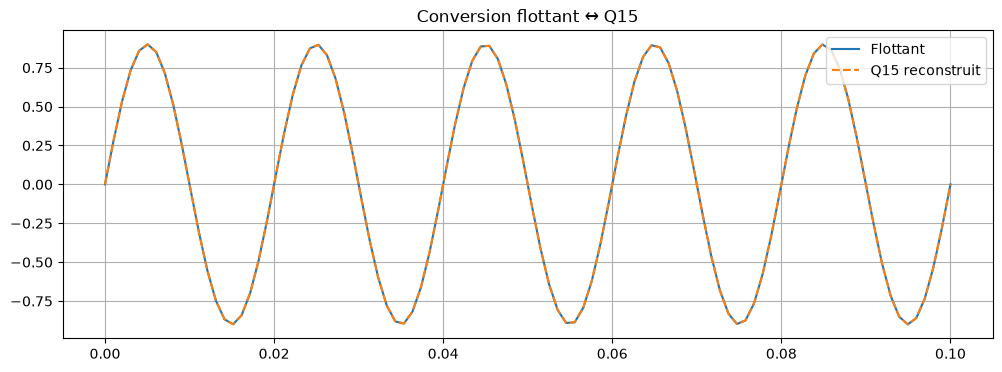

In [3]:
def float_to_q15(x):
    """Convertit un flottant (dans [-1, 1]) en entier Q15 (int16)."""
    x_sat = np.clip(x, -1.0, 1.0)
    return np.round(x_sat * 32767).astype(np.int16)

def q15_to_float(x_q):
    """Convertit un entier Q15 (int16) en flottant."""
    return x_q.astype(np.float32) / 32767.0

# Exemple
t = np.linspace(0, 0.1, 100)
signal_float = 0.9 * np.sin(2*np.pi*50*t)

signal_q15 = float_to_q15(signal_float)
signal_reconstruit = q15_to_float(signal_q15)

plt.figure(figsize=(12, 4))
plt.plot(t, signal_float, label='Flottant')
plt.plot(t, signal_reconstruit, '--', label='Q15 reconstruit')
plt.legend()
plt.grid()
plt.title('Conversion flottant ↔ Q15')
plt.show()

## 2.2 Filtre FIR en Q15 (simulation de arm_fir_q15)

Nous allons simuler un filtre FIR en utilisant des opérations Q15. La fonction `arm_fir_q15` utilise des accumulateurs en Q31 pour éviter les débordements.

C:\Users\RAWAA\AppData\Local\Temp\ipykernel_3332\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


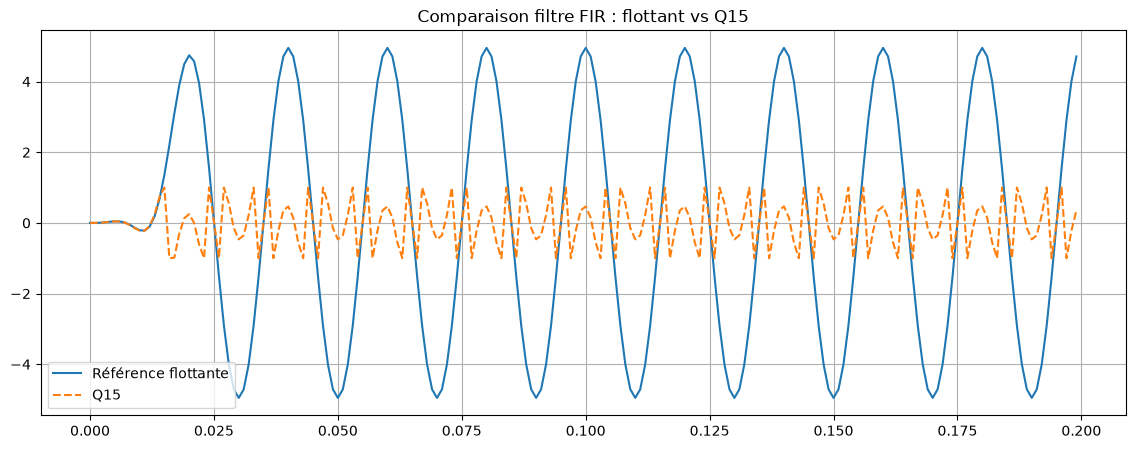

Erreur maximale : 4.574916


In [4]:
def fir_q15(x_q, b_q):
    """Simule un filtre FIR en Q15.
    x_q : entrée en Q15 (int16)
    b_q : coefficients en Q15 (int16)
    Retourne la sortie en Q15.
    """
    M = len(b_q)
    N = len(x_q)
    y_q = np.zeros(N, dtype=np.int16)
    # Buffer d'état (en Q15)
    state = np.zeros(M, dtype=np.int16)
    for n in range(N):
        # Mise à jour du buffer (décalage)
        state[1:] = state[:-1]
        state[0] = x_q[n]
        # Accumulateur en Q31 (32 bits) pour éviter les débordements
        acc = np.int32(0)
        for k in range(M):
            acc += np.int32(state[k]) * np.int32(b_q[k])
        # On décale de 15 pour repasser en Q15 (car produit de deux Q15 donne Q30, on ramène en Q15)
        # Attention : arrondi
        acc = (acc + (1 << 14)) >> 15
        # Saturation
        acc = np.clip(acc, -32768, 32767)
        y_q[n] = acc.astype(np.int16)
    return y_q

# Conception d'un filtre FIR passe-bas en flottant
fs = 1000
fc = 100
N_taps = 31
b_float = signal.firwin(N_taps, fc, fs=fs, window='hamming')

# Normalisation et conversion en Q15
b_float = b_float / np.max(np.abs(b_float))  # normalisation pour rester dans [-1, 1]
b_q15 = float_to_q15(b_float)

# Signal d'entrée en flottant et conversion Q15
t = np.linspace(0, 0.2, 200, endpoint=False)
x_float = np.sin(2*np.pi*50*t) + 0.5*np.sin(2*np.pi*200*t)
x_q15 = float_to_q15(x_float)

# Filtrage en Q15
y_q15 = fir_q15(x_q15, b_q15)
y_float_reconstruit = q15_to_float(y_q15)

# Filtrage en flottant pour référence
y_float_ref = signal.lfilter(b_float, 1, x_float)

# Comparaison
plt.figure(figsize=(14, 5))
plt.plot(t, y_float_ref, label='Référence flottante')
plt.plot(t, y_float_reconstruit, '--', label='Q15')
plt.legend()
plt.grid()
plt.title('Comparaison filtre FIR : flottant vs Q15')
plt.show()

err = np.max(np.abs(y_float_ref - y_float_reconstruit))
print(f"Erreur maximale : {err:.6f}")

## 2.3 FFT en Q15 (simulation de arm_rfft_q15)

La FFT en Q15 nécessite une mise à l'échelle pour éviter les débordements. Nous allons simuler une FFT sur des données Q15 et comparer avec la FFT flottante.

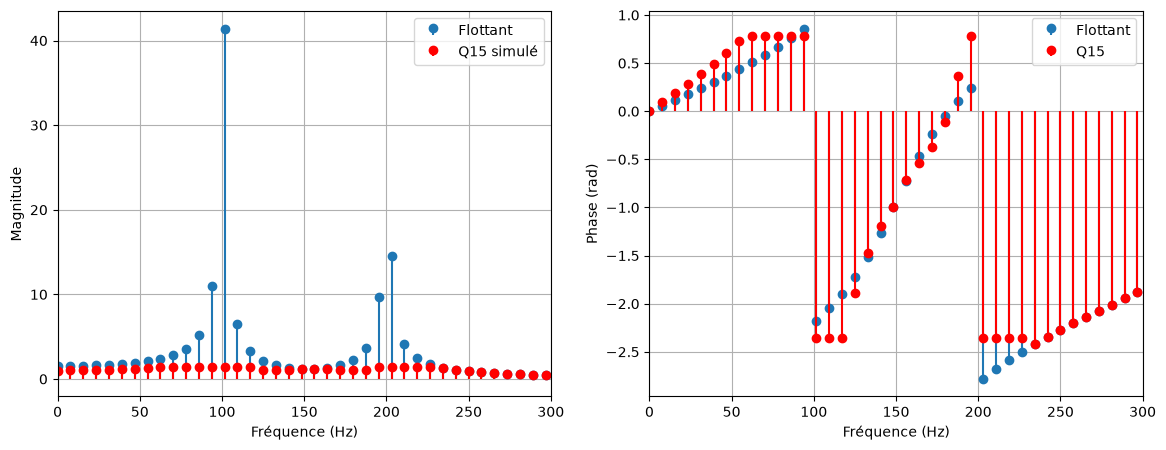

La version Q15 introduit une légère dégradation due à la quantification.


In [5]:
# Simulation d'une FFT en Q15
# Pour simplifier, on utilise la FFT flottante puis on quantifie les résultats en Q15
# Dans CMSIS-DSP, la FFT est implémentée en utilisant des rotations Q15 et des additions/soustractions avec saturation.

N_fft = 128
fs = 1000
t_fft = np.arange(N_fft) / fs
x_float = 0.7 * np.sin(2*np.pi*100*t_fft) + 0.3 * np.sin(2*np.pi*200*t_fft)

# FFT flottante
X_float = fft(x_float)[:N_fft//2]

# Conversion en Q15
x_q15 = float_to_q15(x_float)

# Simulation de la FFT Q15 : on effectue la FFT en flottant puis on quantifie les résultats
# Dans la réalité, la FFT Q15 utilise des étapes de mise à l'échelle.
X_q15_float = fft(q15_to_float(x_q15))[:N_fft//2]
# On quantifie les résultats en Q15 pour simuler la sortie de arm_rfft_q15
# La sortie de arm_rfft_q15 est généralement en Q15 pour la partie réelle et imaginaire.
X_q15_real = float_to_q15(np.real(X_q15_float))
X_q15_imag = float_to_q15(np.imag(X_q15_float))
X_q15 = q15_to_float(X_q15_real) + 1j * q15_to_float(X_q15_imag)

freqs = fftfreq(N_fft, 1/fs)[:N_fft//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.stem(freqs, np.abs(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.abs(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15 simulé')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude')
plt.xlim(0, 300)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.stem(freqs, np.angle(X_float), basefmt=' ', label='Flottant')
plt.stem(freqs, np.angle(X_q15), linefmt='r-', markerfmt='ro', basefmt=' ', label='Q15')
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Phase (rad)')
plt.xlim(0, 300)
plt.legend()
plt.grid()
plt.show()

print("La version Q15 introduit une légère dégradation due à la quantification.")

## 2.4 Fonctions mathématiques (sin, cos, atan2) en Q15

CMSIS‑DSP fournit des tables de recherche pour les fonctions trigonométriques en Q15. Simulons un calcul de sinus en Q15 à l'aide d'une table.

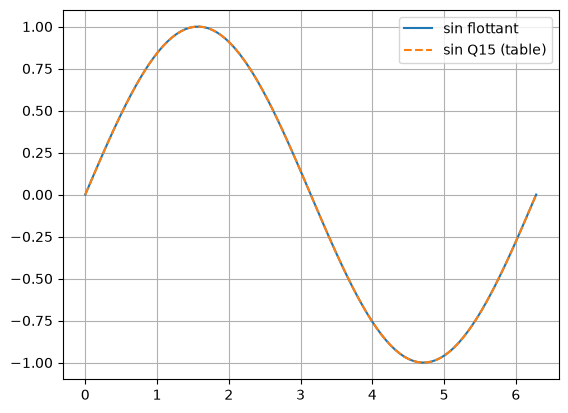

In [7]:
# Table de sinus Q15 pour 360 degrés (ou 2*pi radians)
# En pratique, la table est stockée dans la mémoire du microcontrôleur.
def sin_q15(angle_q15):
    """Simule arm_sin_q15"""

    # Conversion en entier 32 bits pour éviter OverflowError
    angle_q15 = np.int32(angle_q15)

    n_points = 256
    table = np.sin(2*np.pi * np.arange(n_points) / n_points)

    # Calcul de l'index
    idx = (angle_q15 * n_points) // 32768
    idx = np.clip(idx, 0, n_points-1)

    # Interpolation linéaire
    frac = (angle_q15 * n_points) % 32768 / 32768.0

    val = (1-frac) * table[idx] + frac * table[(idx+1) % n_points]

    return float_to_q15(val)
# Test
angles = np.linspace(0, 2*np.pi, 100)
sin_float = np.sin(angles)

sin_q15_vals = np.array([
    sin_q15(float_to_q15(angle/(2*np.pi)))
    for angle in angles
])

sin_reconst = q15_to_float(sin_q15_vals)

plt.plot(angles, sin_float, label='sin flottant')
plt.plot(angles, sin_reconst, '--', label='sin Q15 (table)')
plt.legend()
plt.grid()
plt.show()

# 3. Atelier : Mise en œuvre d'une application DSP embarquée

Nous allons simuler une application complète : un filtre anti-repliement (passe-bas) suivi d'une FFT pour analyser un signal, en utilisant des fonctions en virgule fixe. L'architecture est typique d'un système embarqué temps réel : acquisition (ADC), filtrage, FFT, puis communication ou affichage.

C:\Users\RAWAA\AppData\Local\Temp\ipykernel_3332\3077985749.py:19: RuntimeWarning: overflow encountered in scalar add
  acc += np.int32(state[k]) * np.int32(b_q[k])


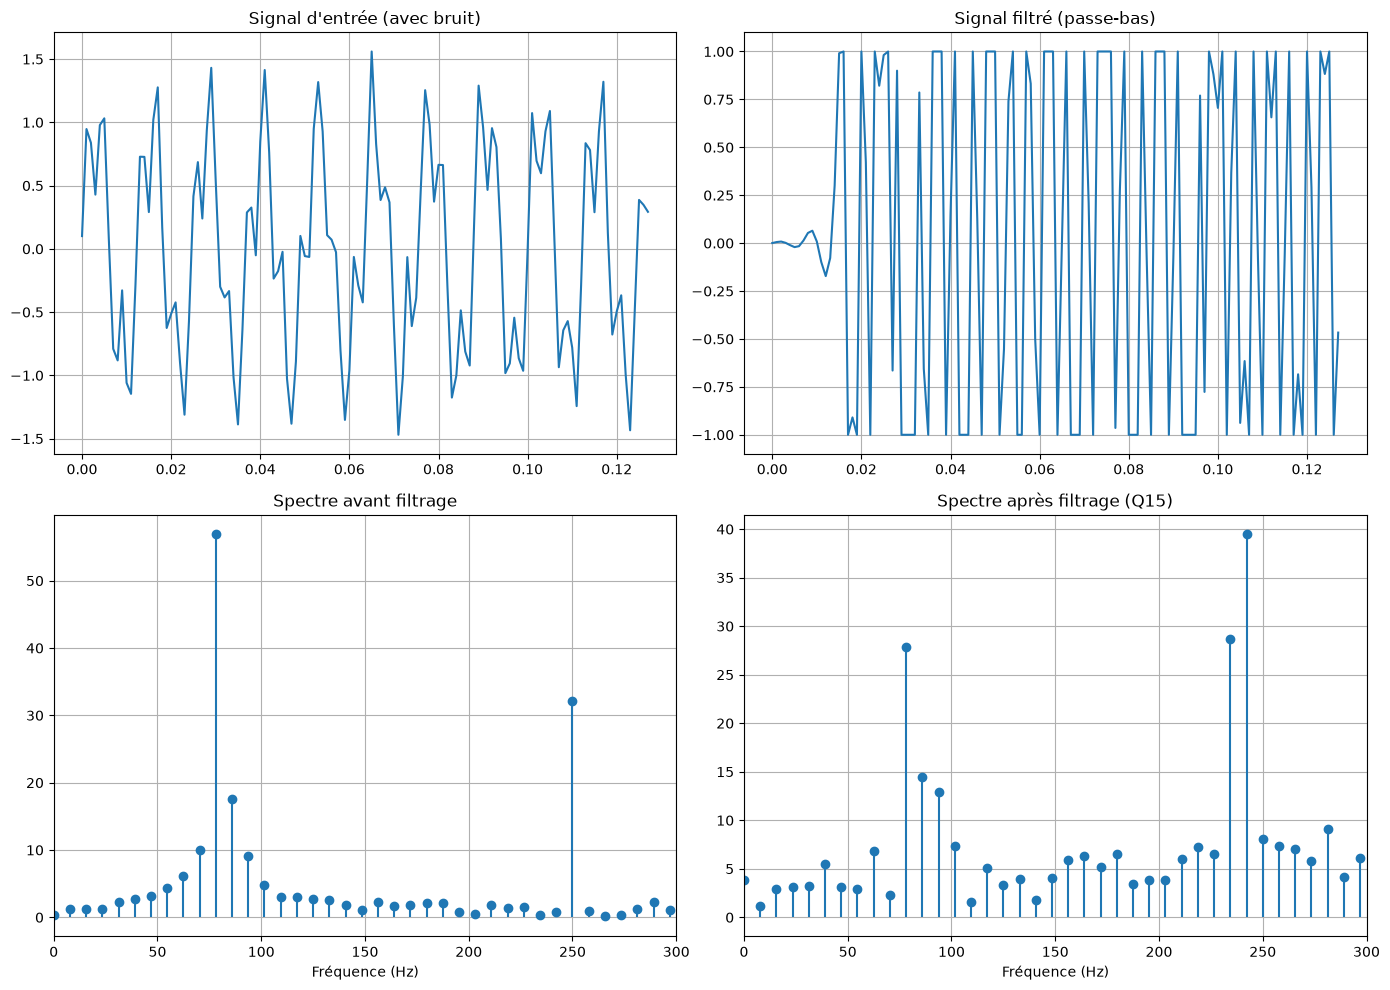

Taille du filtre : 31 coefficients en Q15
Nombre d'échantillons FFT : 128
En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.


In [8]:
# Paramètres système
fs = 1000
N_samples = 128
t = np.arange(N_samples) / fs

# Signal d'entrée simulé (mélange de fréquences)
x_float = np.sin(2*np.pi*80*t) + 0.5*np.sin(2*np.pi*250*t) + 0.1*np.random.randn(N_samples)

# 1. Filtre anti-repliement (passe-bas en Q15)
# Conception du filtre en flottant
fc = 150
b_float = signal.firwin(31, fc, fs=fs, window='hamming')
b_float = b_float / np.max(np.abs(b_float))
b_q15 = float_to_q15(b_float)

# Conversion entrée en Q15
x_q15 = float_to_q15(x_float)

# Filtrage
y_q15 = fir_q15(x_q15, b_q15)
y_float = q15_to_float(y_q15)

# 2. FFT en Q15 sur le signal filtré
# (simulée comme précédemment)
X_q15_real = float_to_q15(np.real(fft(y_float)[:N_samples//2]))
X_q15_imag = float_to_q15(np.imag(fft(y_float)[:N_samples//2]))
X_q15 = q15_to_float(X_q15_real) + 1j*q15_to_float(X_q15_imag)

freqs = fftfreq(N_samples, 1/fs)[:N_samples//2]

# Visualisation
plt.figure(figsize=(14, 10))
plt.subplot(2, 2, 1)
plt.plot(t, x_float)
plt.title('Signal d\'entrée (avec bruit)')
plt.grid()

plt.subplot(2, 2, 2)
plt.plot(t, y_float)
plt.title('Signal filtré (passe-bas)')
plt.grid()

plt.subplot(2, 2, 3)
plt.stem(freqs, np.abs(fft(x_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre avant filtrage')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.subplot(2, 2, 4)
plt.stem(freqs, np.abs(fft(y_float)[:N_samples//2]), basefmt=' ')
plt.title('Spectre après filtrage (Q15)')
plt.xlabel('Fréquence (Hz)')
plt.xlim(0, 300)
plt.grid()

plt.tight_layout()
plt.show()

# Bilan des ressources simulées
print(f"Taille du filtre : {len(b_q15)} coefficients en Q15")
print(f"Nombre d'échantillons FFT : {N_samples}")
print("En pratique, ces opérations peuvent être réalisées par CMSIS-DSP sur un Cortex-M4 en temps réel.")

# 4. Exercices – Semaine 11

## Exercice 1 – Filtre RII en Q15

1. Concevoir un filtre RII Butterworth passe-bas d'ordre 4 avec fc=100 Hz, fs=1000 Hz.
2. Convertir les coefficients en Q15 (normalisation puis quantification).
3. Implémenter une fonction `iir_q15` simulant un filtre RII en Q15 (structure directe II) en utilisant un accumulateur Q31.
4. Tester sur un signal bruité et comparer avec la version flottante.
5. Discuter de la stabilité : que se passe-t-il si l'ordre est trop élevé en Q15 ?

**Code** :

Coefficients b : [0.00482434 0.01929737 0.02894606 0.01929737 0.00482434]
Coefficients a : [ 1.         -2.36951301  2.31398841 -1.05466541  0.18737949]

Coefficients b Q15 : [158 632 949 632 158]
Coefficients a Q15 : [-77644  75825 -34559   6140]


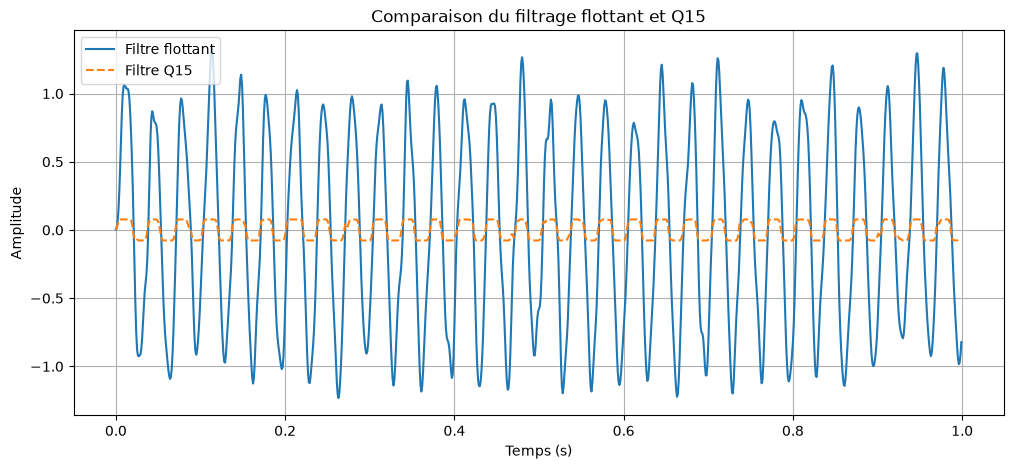

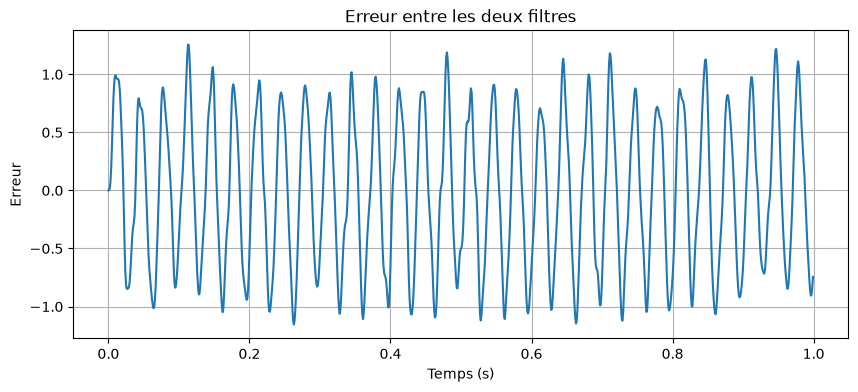

Erreur quadratique moyenne : 0.4333146631937561

Pôles du filtre quantifié :
[0.66052322+0.44333847j 0.66052322-0.44333847j 0.5242302 +0.14585357j
 0.5242302 -0.14585357j]
Rayon maximal : 0.7955123658515096
Filtre Q15 stable


In [12]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# =========================================
# 1. CONCEPTION DU FILTRE BUTTERWORTH
# =========================================

fs = 1000
fc = 100
ordre = 4

b, a = signal.butter(
    ordre,
    fc,
    btype='low',
    fs=fs
)

print("Coefficients b :", b)
print("Coefficients a :", a)


# =========================================
# 2. QUANTIFICATION Q15
# =========================================

def quantifier_q15(c):

    return np.round(c * 32768).astype(np.int64)


# Normalisation par a[0]
b = b / a[0]
a = a / a[0]

b_q = quantifier_q15(b)

# On ne stocke pas a0 car a0 = 1
a_q = quantifier_q15(a[1:])

print("\nCoefficients b Q15 :", b_q)
print("Coefficients a Q15 :", a_q)


# =========================================
# 3. FONCTION DE SATURATION
# =========================================

def saturation_q15(x):

    return max(-32768, min(32767, int(x)))


def saturation_q31(x):

    return max(-2147483648,
               min(2147483647, int(x)))


# =========================================
# 4. FILTRE RII EN Q15
# STRUCTURE DIRECTE II
# =========================================

def iir_q15(x_q, b_q, a_q):

    N = len(x_q)
    ordre = len(a_q)

    # Mémoire des états
    w = np.zeros(ordre, dtype=np.int64)

    # Sortie
    y_q = np.zeros(N, dtype=np.int64)

    for n in range(N):

        # Calcul de l'état interne
        acc = int(x_q[n]) << 16

        for k in range(ordre):
            acc -= 2 * int(a_q[k]) * int(w[k])

        # Accumulateur Q31
        acc = saturation_q31(acc)

        # Conversion Q31 vers Q15
        wn = saturation_q15(round(acc / 65536))

        # Calcul de la sortie
        acc_y = 0

        acc_y += 2 * int(b_q[0]) * wn

        for k in range(1, ordre + 1):
            acc_y += 2 * int(b_q[k]) * int(w[k-1])

        acc_y = saturation_q31(acc_y)

        y_q[n] = saturation_q15(
            round(acc_y / 65536)
        )

        # Mise à jour des états
        if ordre > 1:
            w[1:] = w[:-1]

        w[0] = wn

    return y_q


# =========================================
# 5. GENERATION DU SIGNAL BRUITE
# =========================================

N = 1000

np.random.seed(0)

t = np.arange(N) / fs

# Signal utile
s = np.sin(2*np.pi*30*t)

# Bruit
bruit = 0.3 * np.random.randn(N)

# Signal bruité
x = s + bruit


# =========================================
# 6. FILTRAGE FLOTTANT
# =========================================

y_float = signal.lfilter(b, a, x)


# =========================================
# 7. FILTRAGE Q15
# =========================================

# Conversion du signal en Q15
x_q = np.round(x * 32768).astype(np.int64)

# Saturation du signal
x_q = np.clip(x_q, -32768, 32767)

# Application du filtre
y_q = iir_q15(x_q, b_q, a_q)

# Retour en flottant
y_fixed = y_q / 32768


# =========================================
# 8. COMPARAISON DES RESULTATS
# =========================================

plt.figure(figsize=(12, 5))

plt.plot(t, y_float, label="Filtre flottant")
plt.plot(t, y_fixed, '--', label="Filtre Q15")

plt.title("Comparaison du filtrage flottant et Q15")
plt.xlabel("Temps (s)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()


# =========================================
# 9. ERREUR DE QUANTIFICATION
# =========================================

erreur = y_float - y_fixed

plt.figure(figsize=(10, 4))

plt.plot(t, erreur)

plt.title("Erreur entre les deux filtres")
plt.xlabel("Temps (s)")
plt.ylabel("Erreur")
plt.grid()
plt.show()

print("Erreur quadratique moyenne :",
      np.mean(erreur**2))


# =========================================
# 10. VERIFICATION DE STABILITE
# =========================================

a_quantifie = np.concatenate((
    [1.0],
    a_q / 32768
))

poles = np.roots(a_quantifie)

print("\nPôles du filtre quantifié :")
print(poles)

print("Rayon maximal :",
      np.max(np.abs(poles)))

if np.all(np.abs(poles) < 1):
    print("Filtre Q15 stable")
else:
    print("Filtre Q15 instable")


## Exercice 2 – FFT en Q15 et fenêtrage

1. Générer un signal composé de deux sinusoïdes de fréquences 120 Hz et 130 Hz, fs=1000 Hz, N=64.
2. Appliquer une fenêtre de Hamming en Q15 (convertir la fenêtre en Q15).
3. Calculer la FFT en Q15 (simulée) et tracer le spectre.
4. Comparer la résolution spectrale avec et sans fenêtre.

**Code** :

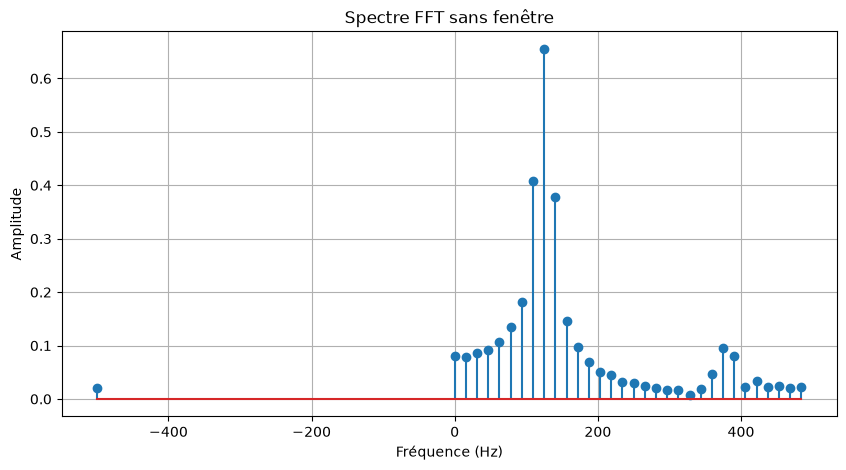

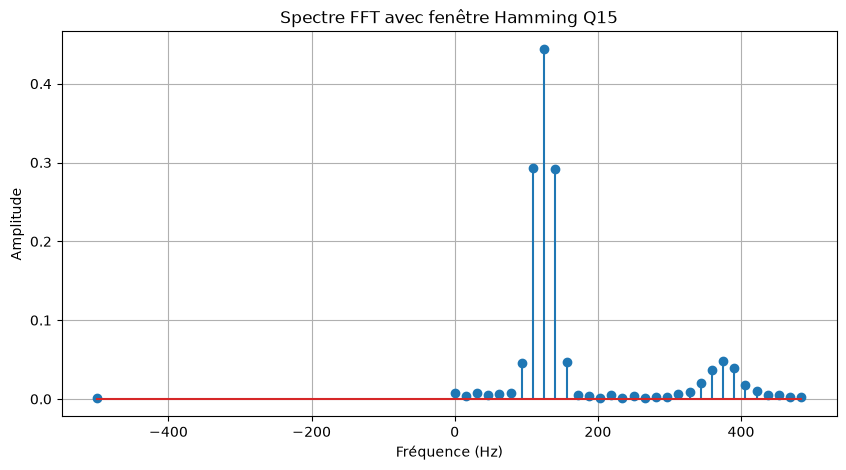

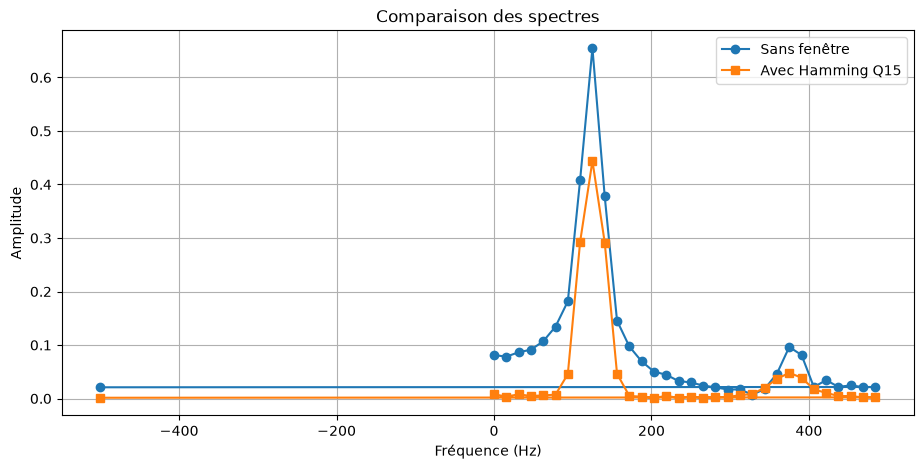

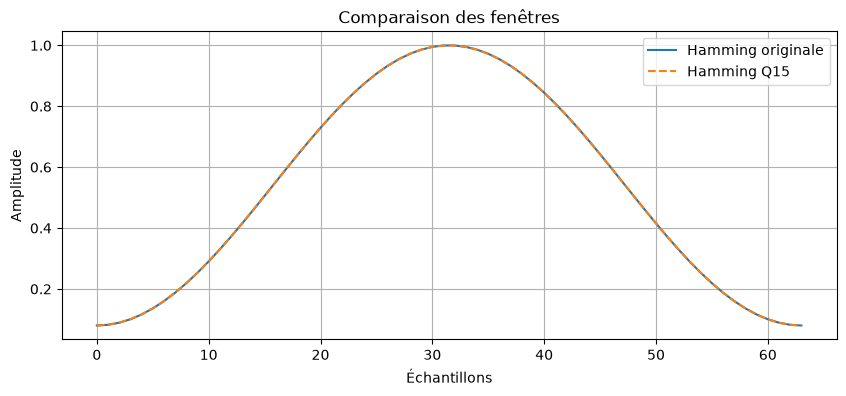

Résolution fréquentielle : 15.625 Hz
Fréquence 1 : 120 Hz
Fréquence 2 : 130 Hz
Écart entre les deux fréquences : 10 Hz


In [13]:

import numpy as np
import matplotlib.pyplot as plt

# =========================================
# 1. PARAMETRES
# =========================================

fs = 1000
N = 64

# Axe temporel
t = np.arange(N) / fs

# =========================================
# 2. GENERATION DU SIGNAL
# =========================================

x = (np.sin(2*np.pi*120*t)
     + np.sin(2*np.pi*130*t))

# =========================================
# 3. FENETRE DE HAMMING EN Q15
# =========================================

# Fenêtre Hamming classique
h = np.hamming(N)

# Conversion Q15
h_q15 = np.round(h * 32768).astype(np.int32)

# Retour en flottant pour la simulation
h_float = h_q15 / 32768

# Application de la fenêtre
x_window = x * h_float

# =========================================
# 4. QUANTIFICATION DU SIGNAL EN Q15
# =========================================

def quantifier_q15(x):

    x_q = np.round(x * 32768)

    return np.clip(x_q, -32768, 32767).astype(np.int32)


x_q15 = quantifier_q15(x)

# Signal sans fenêtre
x_q15_float = x_q15 / 32768

# Signal avec fenêtre
xw_q15 = quantifier_q15(x_q15_float * h_float)

# =========================================
# 5. FFT SIMULEE EN Q15
# =========================================

# FFT sans fenêtre
X1 = np.fft.fft(x_q15_float)

# FFT avec fenêtre
X2 = np.fft.fft(xw_q15 / 32768)

# Normalisation
freq = np.fft.fftfreq(N, 1/fs)

# Garder les fréquences positives
indices = np.arange(N//2 + 1)

freq_pos = freq[indices]

# Spectres en amplitude
S1 = 2 * np.abs(X1[indices]) / N
S2 = 2 * np.abs(X2[indices]) / N

# =========================================
# 6. AFFICHAGE SANS FENETRE
# =========================================

plt.figure(figsize=(10,5))

plt.stem(freq_pos, S1)

plt.title("Spectre FFT sans fenêtre")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# =========================================
# 7. AFFICHAGE AVEC FENETRE HAMMING
# =========================================

plt.figure(figsize=(10,5))

plt.stem(freq_pos, S2)

plt.title("Spectre FFT avec fenêtre Hamming Q15")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

# =========================================
# 8. COMPARAISON DES DEUX SPECTRES
# =========================================

plt.figure(figsize=(11,5))

plt.plot(freq_pos, S1, 'o-', label="Sans fenêtre")
plt.plot(freq_pos, S2, 's-', label="Avec Hamming Q15")

plt.title("Comparaison des spectres")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# =========================================
# 9. AFFICHAGE DE LA FENETRE
# =========================================

plt.figure(figsize=(10,4))

plt.plot(h, label="Hamming originale")
plt.plot(h_float, '--', label="Hamming Q15")

plt.title("Comparaison des fenêtres")
plt.xlabel("Échantillons")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

# =========================================
# 10. RESOLUTION FREQUENTIELLE
# =========================================

delta_f = fs / N

print("Résolution fréquentielle :", delta_f, "Hz")
print("Fréquence 1 : 120 Hz")
print("Fréquence 2 : 130 Hz")
print("Écart entre les deux fréquences : 10 Hz")


## Exercice 3 – Estimation de la consommation mémoire

Pour une application DSP embarquée, on doit estimer la mémoire nécessaire.

1. Un filtre FIR à 64 coefficients en Q15 (int16) est utilisé. Calculer la mémoire pour les coefficients, l'état (buffer circulaire), et le code si nécessaire.
2. Une FFT de 256 points en Q15 nécessite des tables de twiddle factors (rotations). Estimer la mémoire pour ces tables.
3. Proposer une optimisation pour réduire la mémoire (par exemple, utiliser des coefficients symétriques pour le FIR).

**Réponse** :
- Coefficients : 64 * 2 octets = 128 octets.
- Buffer d'état : 64 * 2 = 128 octets.
- Tables FFT (twiddle) : pour N=256, environ N/2 * 2 = 256 octets en Q15.
- Total : environ 512 octets, plus le code. On peut réduire en utilisant la symétrie pour le FIR (coefficients symétriques) ce qui permet de stocker la moitié des coefficients et d'utiliser une structure optimisée.

Correction Exercice 3 :
1. Mémoire du filtre FIR (64 coefficients en Q15)
- Coefficients : \(64 times 2 = 128\) octets.
- Buffer d'état : \(64 times 2 = 128\) octets.
2. Mémoire des tables FFT (256 points)

Chaque facteur contient 2 valeurs (réelle et imaginaire) de 2 octets chacune.
M_FFT = (256 / 2) * 2 * 2

   Resultat : 512 octets

3. Optimisation

Utiliser la symétrie des coefficients FIR pour stocker seulement 32 coefficients au lieu de 64.

Mémoire économisée : 64 octets.

Total :
\[
M=128+128+512
\]

\[
M=768 octets + mémoire du code
\]

## Exercice 4 – Proposition de projet final

Rédiger une proposition de projet intégrant du DSP sur STM32 avec CMSIS‑DSP. La proposition doit inclure :
- Objectif du projet (ex : analyse de signaux ECG, traitement audio, contrôle moteur).
- Spécifications techniques (fréquence d'échantillonnage, nombre de canaux, type de traitement).
- Choix des algorithmes (filtres, FFT, etc.) et justification.
- Estimation des ressources (temps de calcul, mémoire).
- Plan de développement.

**Rédiger la proposition dans une cellule Markdown.**

# Correction Exercice 4 – Proposition de projet final

## Titre du projet : Système intelligent d'analyse et de surveillance des vibrations d'un moteur avec STM32 et CMSIS-DSP

### 1. Objectif du projet

L'objectif de ce projet est de développer un système embarqué capable de surveiller l'état d'un moteur électrique en analysant ses vibrations.

Le système utilise une carte STM32 pour acquérir les signaux provenant d'un capteur de vibration, puis applique des techniques de traitement numérique du signal (DSP) afin de détecter les variations anormales.

Ce projet permet de contribuer à la maintenance préventive des moteurs industriels en détectant certains défauts avant qu'ils ne provoquent une panne.

### 2. Spécifications techniques

- **Carte de développement :** STM32 (exemple : STM32F407).
- **Capteur :** accéléromètre analogique ou numérique.
- **Fréquence d'échantillonnage :** 2 kHz.
- **Nombre de canaux :** 1 canal pour commencer.
- **Résolution :** ADC 12 bits dans le cas d'un capteur analogique.
- **Acquisition :** utilisation de l'ADC avec DMA.
- **Environnement de développement :** STM32CubeIDE.
- **Bibliothèque DSP :** CMSIS-DSP.

Le signal acquis est envoyé vers les algorithmes de traitement pour supprimer le bruit et analyser les vibrations du moteur.

### 3. Choix des algorithmes DSP et justification

**a. Filtre passe-bas FIR**

Un filtre FIR passe-bas sera utilisé pour réduire les composantes de bruit à haute fréquence.

Justification :
- Il permet d'améliorer la qualité du signal.
- Il possède une bonne stabilité.
- Il peut être utilisé avec une phase linéaire.

Fonction CMSIS-DSP : `arm_fir_f32()`.

**b. Transformée de Fourier rapide (FFT)**

La FFT sera utilisée pour transformer le signal du domaine temporel vers le domaine fréquentiel.

Justification :
- Elle permet d'identifier les fréquences dominantes des vibrations.
- Elle facilite la détection de certaines anomalies du moteur.
- Elle permet d'observer l'évolution du spectre fréquentiel.

Fonction CMSIS-DSP : `arm_rfft_fast_f32()`.

**c. Calcul de la valeur efficace (RMS)**

Le calcul RMS permettra de mesurer le niveau global des vibrations.

Justification :
- Il donne une indication de l'amplitude des vibrations.
- Il permet de comparer les mesures dans différentes conditions de fonctionnement.

Fonction CMSIS-DSP : `arm_rms_f32()`.

### 4. Estimation des ressources

Les ressources nécessaires sont estimées pour une acquisition par blocs de 256 échantillons.

- **Fréquence d'échantillonnage :** 2000 Hz.
- **Taille du bloc :** 256 échantillons.
- **Durée d'acquisition d'un bloc :** 256 / 2000 = 128 ms.
- **Résolution fréquentielle de la FFT :** 2000 / 256 = 7,8125 Hz.

**Estimation mémoire :**

- Buffer d'acquisition : 256 × 4 = 1024 octets (si les échantillons sont stockés en float32).
- Buffer FFT : environ 1024 octets.
- Coefficients du filtre FIR : dépend du nombre de coefficients choisi.
- Variables de calcul et résultats : quelques centaines d'octets supplémentaires.

La mémoire totale dépendra de la taille du filtre et de l'organisation des buffers.

**Temps de calcul :**

Les opérations FIR, FFT et RMS seront réalisées avec CMSIS-DSP, une bibliothèque optimisée pour les processeurs ARM Cortex-M.

Le temps réel sera vérifié en mesurant le temps d'exécution de chaque bloc. Le traitement devra être terminé avant l'arrivée du bloc suivant, soit en moins de 128 ms.

### 5. Plan de développement

**Étape 1 : Étude du matériel**

- Choisir la carte STM32 et le capteur de vibration.
- Étudier les caractéristiques du capteur.
- Réaliser les connexions nécessaires.

**Étape 2 : Acquisition du signal**

- Configurer l'ADC.
- Configurer le DMA pour l'acquisition automatique.
- Stocker les échantillons dans un buffer.

**Étape 3 : Implémentation des algorithmes DSP**

- Implémenter le filtre FIR avec CMSIS-DSP.
- Réaliser la FFT du signal filtré.
- Calculer la valeur RMS.

**Étape 4 : Tests et validation**

- Tester le système avec différents signaux.
- Comparer les résultats avec une simulation Python.
- Vérifier le temps d'exécution et la consommation mémoire.

**Étape 5 : Affichage des résultats**

- Afficher la valeur RMS et les fréquences dominantes.
- Signaler une variation anormale des vibrations à l'aide d'une LED ou d'une interface de visualisation.

### 6. Résultat attendu

À la fin du projet, le système devra être capable d'acquérir les vibrations d'un moteur, de filtrer le signal, d'analyser son spectre fréquentiel et de calculer son niveau RMS.

Cette solution permettra de réaliser une première application de maintenance préventive basée sur le traitement numérique du signal avec STM32 et CMSIS-DSP.

## Exercice 5 – Simulation d'une application temps réel

On souhaite simuler un traitement temps réel sur un microcontrôleur. On considère un buffer circulaire de 128 échantillons, un filtre FIR de 31 coefficients, et une FFT de 128 points.

1. Écrire un code Python qui simule le traitement en continu : chaque itération, on ajoute un nouvel échantillon, on met à jour le buffer, on applique le filtre et on calcule la FFT sur les 128 derniers échantillons.
2. Mesurer le temps d'exécution de chaque étape (utiliser `time.perf_counter`).
3. Estimer si un Cortex-M4 à 100 MHz peut respecter une période d'échantillonnage de 1 ms.
4. Proposer des optimisations (ex : utiliser la FFT uniquement tous les N échantillons).

**Code** :

In [16]:

import numpy as np
import time

# ==========================================
# 1. PARAMETRES
# ==========================================

buffer_size = 128
filter_size = 31
N_FFT = 128
iterations = 200
N_FFT_period = 10

# Buffer circulaire
buffer = np.zeros(buffer_size)
index = 0

# ==========================================
# 2. COEFFICIENTS DU FILTRE FIR
# ==========================================

# Filtre passe-bas
fc = 0.2

k = np.arange(filter_size) - (filter_size - 1) / 2

h = 2 * fc * np.sinc(2 * fc * k)
h *= np.hamming(filter_size)
h /= np.sum(h)

# ==========================================
# 3. MESURE DES TEMPS
# ==========================================

time_acquisition = 0
time_buffer = 0
time_filter = 0
time_fft = 0

filtered_signal = 0
spectrum = None

# ==========================================
# 4. SIMULATION TEMPS REEL
# ==========================================

for n in range(iterations):

    # Acquisition
    t0 = time.perf_counter()
    new_sample = np.random.randn()
    t1 = time.perf_counter()

    time_acquisition += t1 - t0

    # Mise à jour du buffer circulaire
    t0 = time.perf_counter()

    buffer[index] = new_sample
    index = (index + 1) % buffer_size

    t1 = time.perf_counter()
    time_buffer += t1 - t0

    # Filtrage FIR
    t0 = time.perf_counter()

    # Remettre les échantillons dans l'ordre chronologique
    ordered_buffer = np.concatenate(
        (buffer[index:], buffer[:index])
    )

    if n >= filter_size - 1:
        recent_samples = ordered_buffer[-filter_size:]
        filtered_signal = np.dot(h, recent_samples[::-1])

    t1 = time.perf_counter()
    time_filter += t1 - t0

    # FFT tous les 10 échantillons
    if (n + 1) % N_FFT_period == 0:

        t0 = time.perf_counter()

        spectrum = np.fft.fft(ordered_buffer, n=N_FFT)

        t1 = time.perf_counter()
        time_fft += t1 - t0

# ==========================================
# 5. AFFICHAGE DES RESULTATS
# ==========================================

print("===== TEMPS D'EXECUTION =====")

print("Acquisition :", time_acquisition * 1000, "ms")
print("Buffer      :", time_buffer * 1000, "ms")
print("Filtrage    :", time_filter * 1000, "ms")
print("FFT         :", time_fft * 1000, "ms")

print("\nNombre d'iterations :", iterations)
print("Nombre de FFT :", iterations // N_FFT_period)

print("\nDernier signal filtre :", filtered_signal)
total_time = (
    time_acquisition +
    time_buffer +
    time_filter +
    time_fft
)

print("Temps total :", total_time * 1000, "ms")


===== TEMPS D'EXECUTION =====
Acquisition : 0.5472000229929108 ms
Buffer      : 0.22979996720096096 ms
Filtrage    : 2.2024000172677916 ms
FFT         : 0.8213000182877295 ms

Nombre d'iterations : 200
Nombre de FFT : 20

Dernier signal filtre : -1.3789440348815625
Temps total : 3.800700025749393 ms


La simulation permet de reproduire un traitement numérique en temps réel à l'aide d'un buffer circulaire, d'un filtre FIR de 31 coefficients et d'une FFT de 128 points.

La mesure du temps d'exécution permet d'évaluer le coût de chaque étape.

Un Cortex-M4 fonctionnant à 100 MHz dispose de 100 000 cycles pour respecter une période d'échantillonnage de 1 ms.

Pour améliorer les performances, on peut calculer la FFT uniquement tous les 10 échantillons, utiliser les bibliothèques CMSIS-DSP et optimiser la gestion du buffer circulaire.

Ces optimisations permettent de réduire la charge du processeur et de faciliter le respect des contraintes temps réel.

# 5. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Date de rendu** : à définir par l'enseignant.

---